<a href="https://colab.research.google.com/github/MalezhykDaniil/ML/blob/main/%D0%9B%D0%A0_13_%D0%9C%D0%9D_%D0%9C%D0%B0%D0%BB%D0%B5%D0%B6%D0%B8%D0%BA_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [5]:
import kagglehub
dataset_path = kagglehub.dataset_download("gpiosenka/cards-image-datasetclassification")
print('Data source import complete.')

Using Colab cache for faster access to the 'cards-image-datasetclassification' dataset.
Data source import complete.


In [6]:
train_dir = os.path.join(dataset_path, 'train')
valid_dir = os.path.join(dataset_path, 'valid')
test_dir  = os.path.join(dataset_path, 'test')

csv_path = os.path.join(dataset_path, 'cards.csv')

In [7]:
df_cards = pd.read_csv(csv_path)
display(df_cards.head())
print("Розмір таблиці метаданих:", df_cards.shape)

,class index,filepaths,labels,card type,data set
0,0,train/ace of clubs/001.jpg,ace of clubs,ace,train
1,0,train/ace of clubs/002.jpg,ace of clubs,ace,train
2,0,train/ace of clubs/003.jpg,ace of clubs,ace,train
3,0,train/ace of clubs/004.jpg,ace of clubs,ace,train
4,0,train/ace of clubs/005.jpg,ace of clubs,ace,train


Розмір таблиці метаданих: (8155, 5)


In [8]:
# Підрахунок кількості зображень у кожній вибірці
def count_images(directory):
    classes = sorted([d for d in os.listdir(directory) if os.path.isdir(os.path.join(directory, d))])
    counts = {cls: len(os.listdir(os.path.join(directory, cls))) for cls in classes}
    return counts

train_counts = count_images(train_dir)
valid_counts = count_images(valid_dir)
test_counts  = count_images(test_dir)

NUM_CLASSES = len(train_counts)
print(f"Загальна кількість класів: {NUM_CLASSES}")
print(f"Кількість зображень у Train: {sum(train_counts.values())}, Valid: {sum(valid_counts.values())}, Test: {sum(test_counts.values())}")

Загальна кількість класів: 53
Кількість зображень у Train: 7624, Valid: 265, Test: 265


/tmp/ipykernel_440/1918284330.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_dist, x='Class', y='Train', palette='rocket')


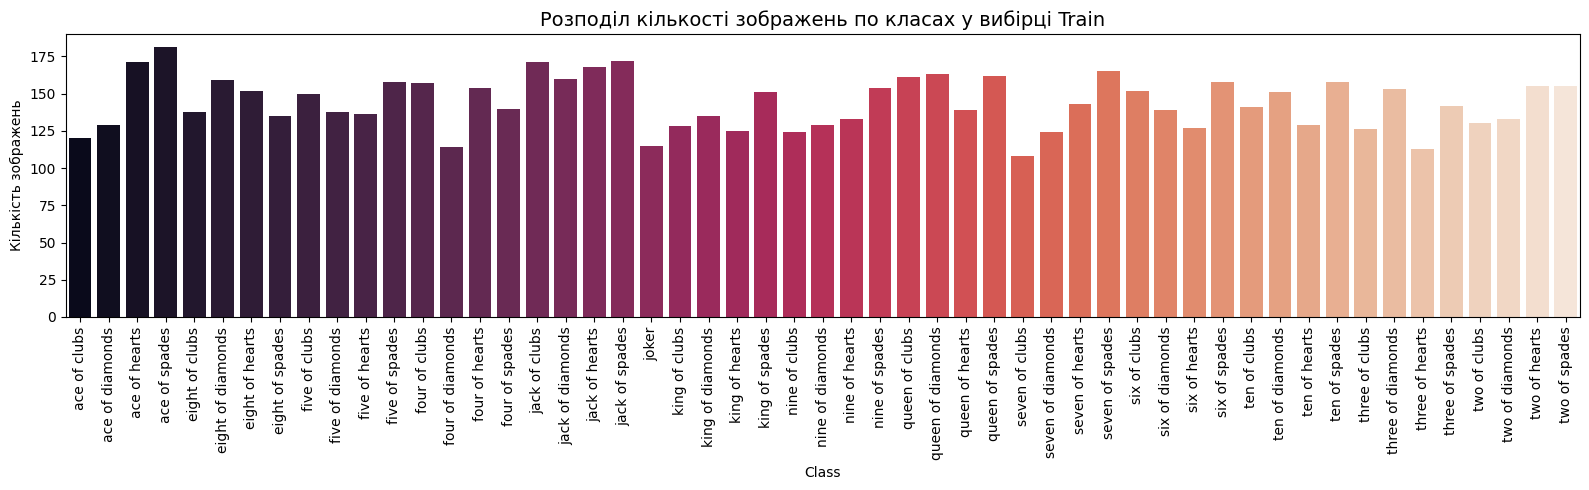

Мінімальна кількість у класі (Train): 108
Максимальна кількість у класі (Train): 181
Середня кількість у класі (Train): 143.8


In [9]:
# Аналіз балансу класів у навчальній вибірці
df_dist = pd.DataFrame({
    'Class': list(train_counts.keys()),
    'Train': list(train_counts.values()),
    'Valid': [valid_counts[c] for c in train_counts.keys()],
    'Test':  [test_counts[c] for c in train_counts.keys()]
})

plt.figure(figsize=(16, 5))
sns.barplot(data=df_dist, x='Class', y='Train', palette='rocket')
plt.title('Розподіл кількості зображень по класах у вибірці Train', fontsize=14)
plt.xticks(rotation=90)
plt.ylabel('Кількість зображень')
plt.tight_layout()
plt.show()

print("Мінімальна кількість у класі (Train):", df_dist['Train'].min())
print("Максимальна кількість у класі (Train):", df_dist['Train'].max())
print("Середня кількість у класі (Train):", round(df_dist['Train'].mean(), 1))

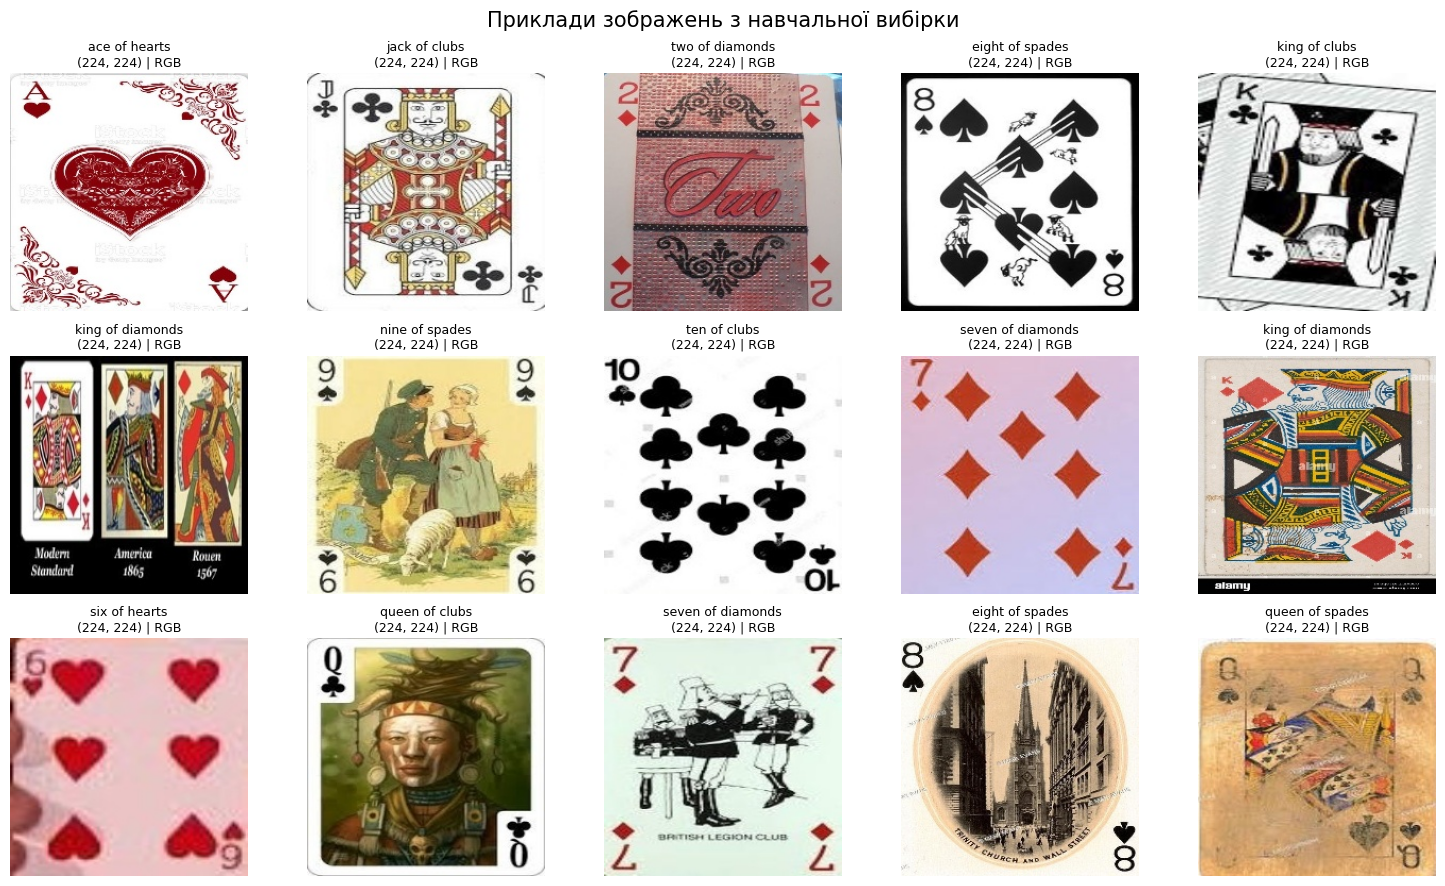

In [10]:
# Виведення випадкових зразків зображень із перевіркою їх розмірів та каналів
class_names = sorted(list(train_counts.keys()))

plt.figure(figsize=(15, 9))
for i in range(15):
    cls = random.choice(class_names)
    cls_folder = os.path.join(train_dir, cls)
    img_name = random.choice(os.listdir(cls_folder))
    img_path = os.path.join(cls_folder, img_name)

    img = Image.open(img_path)
    plt.subplot(3, 5, i + 1)
    plt.imshow(img)
    plt.title(f"{cls}\n{img.size} | {img.mode}", fontsize=9)
    plt.axis('off')

plt.suptitle('Приклади зображень з навчальної вибірки', fontsize=15)
plt.tight_layout()
plt.show()

- Датасет містить **53 класи** (52 стандартні карти колоди + 1 клас `joker`).
- Набір даних уже розділений на `train` (~7624 зображення), `valid` (265 зображень — по 5 на клас) та `test` (265 зображень — по 5 на клас).
- Усі зображення мають стандартну роздільну здатність **224×224 пікселів** у форматі RGB.
- Класи добре збалансовані (приблизно 120–180 зображень на клас у тренувальній вибірці).

In [11]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_datagen_cnn = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    brightness_range=[0.85, 1.15],
    fill_mode='nearest'
)

val_test_datagen_cnn = ImageDataGenerator(rescale=1./255)

train_gen_cnn = train_datagen_cnn.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=SEED
)

valid_gen_cnn = val_test_datagen_cnn.flow_from_directory(
    valid_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_gen_cnn = val_test_datagen_cnn.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

idx_to_class = {v: k for k, v in train_gen_cnn.class_indices.items()}

Found 7624 images belonging to 53 classes.
Found 265 images belonging to 53 classes.
Found 265 images belonging to 53 classes.


In [12]:
def build_custom_cnn(learning_rate=1e-3, dropout_rate=0.4, dense_units=256):
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),
        layers.Dense(dense_units, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# Простий підбір гіперпараметрів на короткому прогоні
param_grid = [
    {'learning_rate': 1e-3, 'dropout_rate': 0.3, 'dense_units': 256},
    {'learning_rate': 5e-4, 'dropout_rate': 0.5, 'dense_units': 512},
]

best_val_acc = 0.0
best_params = None

print("Початок підбору гіперпараметрів для Custom CNN...")
for i, params in enumerate(param_grid, 1):
    print(f"\nКонфігурація {i}: {params}")
    temp_model = build_custom_cnn(**params)
    hist = temp_model.fit(
        train_gen_cnn,
        validation_data=valid_gen_cnn,
        epochs=5,
        verbose=1
    )
    val_acc = max(hist.history['val_accuracy'])
    print(f"Максимальна val_accuracy за 5 епох: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_params = params

print(f"\nОбрані найкращі параметри: {best_params} (val_accuracy: {best_val_acc:.4f})")

Початок підбору гіперпараметрів для Custom CNN...

Конфігурація 1: {'learning_rate': 0.001, 'dropout_rate': 0.3, 'dense_units': 256}
Epoch 1/5
239/239 ━━━━━━━━━━━━━━━━━━━━ 230s 869ms/step - accuracy: 0.0791 - loss: 3.7097 - val_accuracy: 0.0189 - val_loss: 6.5697
Epoch 2/5
239/239 ━━━━━━━━━━━━━━━━━━━━ 133s 555ms/step - accuracy: 0.1171 - loss: 3.2837 - val_accuracy: 0.0491 - val_loss: 5.7514
Epoch 3/5
239/239 ━━━━━━━━━━━━━━━━━━━━ 130s 543ms/step - accuracy: 0.1491 - loss: 3.0159 - val_accuracy: 0.0943 - val_loss: 3.6461
Epoch 4/5
239/239 ━━━━━━━━━━━━━━━━━━━━ 131s 548ms/step - accuracy: 0.1999 - loss: 2.7505 - val_accuracy: 0.1849 - val_loss: 2.7062
Epoch 5/5
239/239 ━━━━━━━━━━━━━━━━━━━━ 124s 517ms/step - accuracy: 0.2707 - loss: 2.4196 - val_accuracy: 0.2491 - val_loss: 2.3649
Максимальна val_accuracy за 5 епох: 0.2491

Конфігурація 2: {'learning_rate': 0.0005, 'dropout_rate': 0.5, 'dense_units': 512}
Epoch 1/5
239/239 ━━━━━━━━━━━━━━━━━━━━ 140s 548ms/step - accuracy: 0.0603 - loss: 4.2

In [13]:
# Навчання фінальної Custom CNN з найкращими параметрами та ранньою зупинкою
cnn_model = build_custom_cnn(**best_params)
cnn_model.summary()

early_stop_cnn = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=6,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_cnn = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

history_cnn = cnn_model.fit(
    train_gen_cnn,
    validation_data=valid_gen_cnn,
    epochs=30,
    callbacks=[early_stop_cnn, reduce_lr_cnn],
    verbose=1
)

cnn_test_loss, cnn_test_acc = cnn_model.evaluate(test_gen_cnn, verbose=0)
print(f"\n[Custom CNN] Test Loss: {cnn_test_loss:.4f} | Test Accuracy: {cnn_test_acc:.4f}")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 53)             │        13,621 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 470,773 (1.80 MB)

 Trainable params: 469,301 (1.79 MB)

 Non-trainable params: 1,472 (5.75 KB)

Epoch 1/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 138s 544ms/step - accuracy: 0.0740 - loss: 3.7616 - val_accuracy: 0.0226 - val_loss: 7.7435 - learning_rate: 0.0010
Epoch 2/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 120s 504ms/step - accuracy: 0.1116 - loss: 3.3181 - val_accuracy: 0.0491 - val_loss: 4.8068 - learning_rate: 0.0010
Epoch 3/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 129s 538ms/step - accuracy: 0.1444 - loss: 3.0192 - val_accuracy: 0.1132 - val_loss: 2.9970 - learning_rate: 0.0010
Epoch 4/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 124s 517ms/step - accuracy: 0.1901 - loss: 2.7616 - val_accuracy: 0.1057 - val_loss: 3.5281 - learning_rate: 0.0010
Epoch 5/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 128s 534ms/step - accuracy: 0.2508 - loss: 2.4982 - val_accuracy: 0.2189 - val_loss: 2.4880 - learning_rate: 0.0010
Epoch 6/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 120s 501ms/step - accuracy: 0.2988 - loss: 2.2813 - val_accuracy: 0.3774 - val_loss: 2.0320 - learning_rate: 0.0010
Epoch 7/30
239/239 ━━━━━━━━━━━━━━━━━━━━ 125s 524ms/step - accura

Модель VGG

In [14]:
# Генератори даних спеціально для VGG16
train_datagen_vgg = ImageDataGenerator(
    preprocessing_function=vgg16_preprocess,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    fill_mode='nearest'
)

val_test_datagen_vgg = ImageDataGenerator(preprocessing_function=vgg16_preprocess)

train_gen_vgg = train_datagen_vgg.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True,
    seed=SEED
)

valid_gen_vgg = val_test_datagen_vgg.flow_from_directory(
    valid_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_gen_vgg = val_test_datagen_vgg.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 7624 images belonging to 53 classes.
Found 265 images belonging to 53 classes.
Found 265 images belonging to 53 classes.


In [15]:
# Етап 1: Заморожуємо базові шари VGG16 та навчаємо лише класифікаційну голову
base_vgg16 = VGG16(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_vgg16.trainable = False

vgg_model = models.Sequential([
    base_vgg16,
    layers.GlobalAveragePooling2D(),
    layers.Dense(512, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation='softmax')
])

vgg_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_vgg_stage1 = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

print("Етап 1: Навчання класифікаційної голови VGG16 (Feature Extraction)...")
history_vgg_stage1 = vgg_model.fit(
    train_gen_vgg,
    validation_data=valid_gen_vgg,
    epochs=12,
    callbacks=[early_stop_vgg_stage1],
    verbose=1
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Етап 1: Навчання класифікаційної голови VGG16 (Feature Extraction)...
Epoch 1/12
239/239 ━━━━━━━━━━━━━━━━━━━━ 161s 628ms/step - accuracy: 0.1933 - loss: 3.2844 - val_accuracy: 0.3585 - val_loss: 2.1221
Epoch 2/12
239/239 ━━━━━━━━━━━━━━━━━━━━ 120s 501ms/step - accuracy: 0.3489 - loss: 2.3131 - val_accuracy: 0.4566 - val_loss: 1.7780
Epoch 3/12
239/239 ━━━━━━━━━━━━━━━━━━━━ 123s 513ms/step - accuracy: 0.4132 - loss: 2.0024 - val_accuracy: 0.4679 - val_loss: 1.7006
Epoch 4/12
239/239 ━━━━━━━━━━━━━━━━━━━━ 129s 538ms/step - accuracy: 0.4658 - loss: 1.7863 - val_accuracy: 0.4981 - val_loss: 1.6040
Epoch 5/12
239/239 ━━━━━━━━━━━━━━━━━━━━ 128s 534ms/step - accuracy: 0.5010 - loss: 1.6784 - val_accuracy: 0.4943 - val_loss: 1.6903
Epoch 6/12
239/239 ━━━━━━━━━━━━━━━━━━━━ 125s 524ms/step - accuracy: 0.5311 - loss: 1.5434 - val_accuracy: 0.5170 - val_loss: 1.5910
Epoch 7/12
239/239 ━━━━━━━━━━━━━━━━━━━━ 126s 525ms/step - accuracy: 0.5559 - loss: 1.44

In [16]:
# Етап 2: Донавчання (Fine-Tuning) верхніх згорткових блоків VGG16
base_vgg16.trainable = True

for layer in base_vgg16.layers:
    if layer.name.startswith('block5') or layer.name.startswith('block4'):
        layer.trainable = True
    else:
        layer.trainable = False

vgg_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_vgg_stage2 = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_vgg = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

print("Етап 2: Донавчання (Fine-Tuning) VGG16...")
history_vgg_stage2 = vgg_model.fit(
    train_gen_vgg,
    validation_data=valid_gen_vgg,
    epochs=20,
    callbacks=[early_stop_vgg_stage2, reduce_lr_vgg],
    verbose=1
)

vgg_test_loss, vgg_test_acc = vgg_model.evaluate(test_gen_vgg, verbose=0)
print(f"\n[VGG16 Fine-Tuned] Test Loss: {vgg_test_loss:.4f} | Test Accuracy: {vgg_test_acc:.4f}")

Етап 2: Донавчання (Fine-Tuning) VGG16...
Epoch 1/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 171s 611ms/step - accuracy: 0.6674 - loss: 1.0635 - val_accuracy: 0.7132 - val_loss: 0.8493 - learning_rate: 1.0000e-05
Epoch 2/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 135s 563ms/step - accuracy: 0.7365 - loss: 0.8520 - val_accuracy: 0.7623 - val_loss: 0.7275 - learning_rate: 1.0000e-05
Epoch 3/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 131s 548ms/step - accuracy: 0.7884 - loss: 0.7034 - val_accuracy: 0.8000 - val_loss: 0.6167 - learning_rate: 1.0000e-05
Epoch 4/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 129s 539ms/step - accuracy: 0.8092 - loss: 0.6290 - val_accuracy: 0.8264 - val_loss: 0.5304 - learning_rate: 1.0000e-05
Epoch 5/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 133s 557ms/step - accuracy: 0.8434 - loss: 0.5578 - val_accuracy: 0.8453 - val_loss: 0.4668 - learning_rate: 1.0000e-05
Epoch 6/20
239/239 ━━━━━━━━━━━━━━━━━━━━ 132s 554ms/step - accuracy: 0.8639 - loss: 0.4935 - val_accuracy: 0.8792 - val_loss: 0.4104 - learning_rate: 1.0000e-0

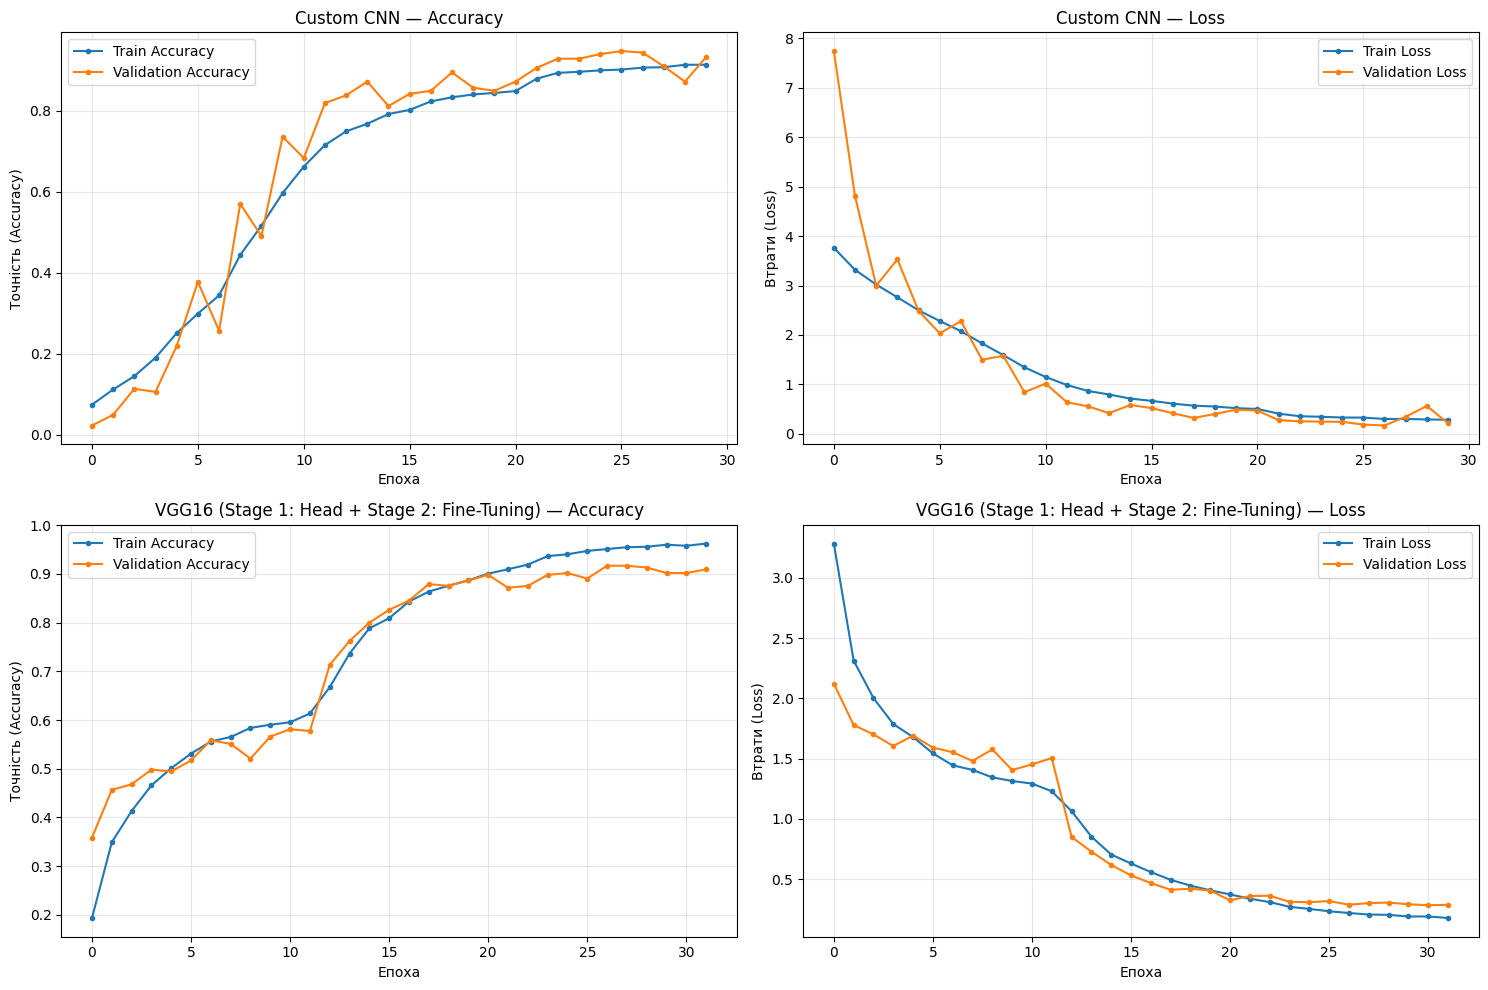

In [17]:
def plot_learning_curves(histories, titles):
    fig, axes = plt.subplots(len(histories), 2, figsize=(15, 5 * len(histories)))
    if len(histories) == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, (hist, title) in enumerate(zip(histories, titles)):
        axes[idx, 0].plot(hist['accuracy'], label='Train Accuracy', marker='o', markersize=3)
        axes[idx, 0].plot(hist['val_accuracy'], label='Validation Accuracy', marker='o', markersize=3)
        axes[idx, 0].set_title(f'{title} — Accuracy')
        axes[idx, 0].set_xlabel('Епоха')
        axes[idx, 0].set_ylabel('Точність (Accuracy)')
        axes[idx, 0].legend()
        axes[idx, 0].grid(True, alpha=0.3)

        axes[idx, 1].plot(hist['loss'], label='Train Loss', marker='o', markersize=3)
        axes[idx, 1].plot(hist['val_loss'], label='Validation Loss', marker='o', markersize=3)
        axes[idx, 1].set_title(f'{title} — Loss')
        axes[idx, 1].set_xlabel('Епоха')
        axes[idx, 1].set_ylabel('Втрати (Loss)')
        axes[idx, 1].legend()
        axes[idx, 1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

vgg_combined_history = {
    'accuracy': history_vgg_stage1.history['accuracy'] + history_vgg_stage2.history['accuracy'],
    'val_accuracy': history_vgg_stage1.history['val_accuracy'] + history_vgg_stage2.history['val_accuracy'],
    'loss': history_vgg_stage1.history['loss'] + history_vgg_stage2.history['loss'],
    'val_loss': history_vgg_stage1.history['val_loss'] + history_vgg_stage2.history['val_loss'],
}

plot_learning_curves(
    [history_cnn.history, vgg_combined_history],
    ['Custom CNN', 'VGG16 (Stage 1: Head + Stage 2: Fine-Tuning)']
)

In [18]:
# Отримання прогнозів найкращої моделі (VGG16) на тестовій вибірці
test_gen_vgg.reset()
pred_probs = vgg_model.predict(test_gen_vgg, verbose=1)
pred_classes = np.argmax(pred_probs, axis=1)
true_classes = test_gen_vgg.classes

print("Звіт класифікації (Classification Report) для VGG16:")
print(classification_report(true_classes, pred_classes, target_names=class_names))

9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 222ms/step
Звіт класифікації (Classification Report) для VGG16:
                   precision    recall  f1-score   support

     ace of clubs       0.80      0.80      0.80         5
  ace of diamonds       1.00      1.00      1.00         5
    ace of hearts       1.00      1.00      1.00         5
    ace of spades       1.00      1.00      1.00         5
   eight of clubs       0.83      1.00      0.91         5
eight of diamonds       0.67      0.80      0.73         5
  eight of hearts       1.00      1.00      1.00         5
  eight of spades       1.00      0.80      0.89         5
    five of clubs       1.00      0.80      0.89         5
 five of diamonds       0.75      0.60      0.67         5
   five of hearts       1.00      1.00      1.00         5
   five of spades       0.83      1.00      0.91         5
    four of clubs       0.80      0.80      0.80         5
 four of diamonds       1.00      1.00      1.00         5
   four of hearts     

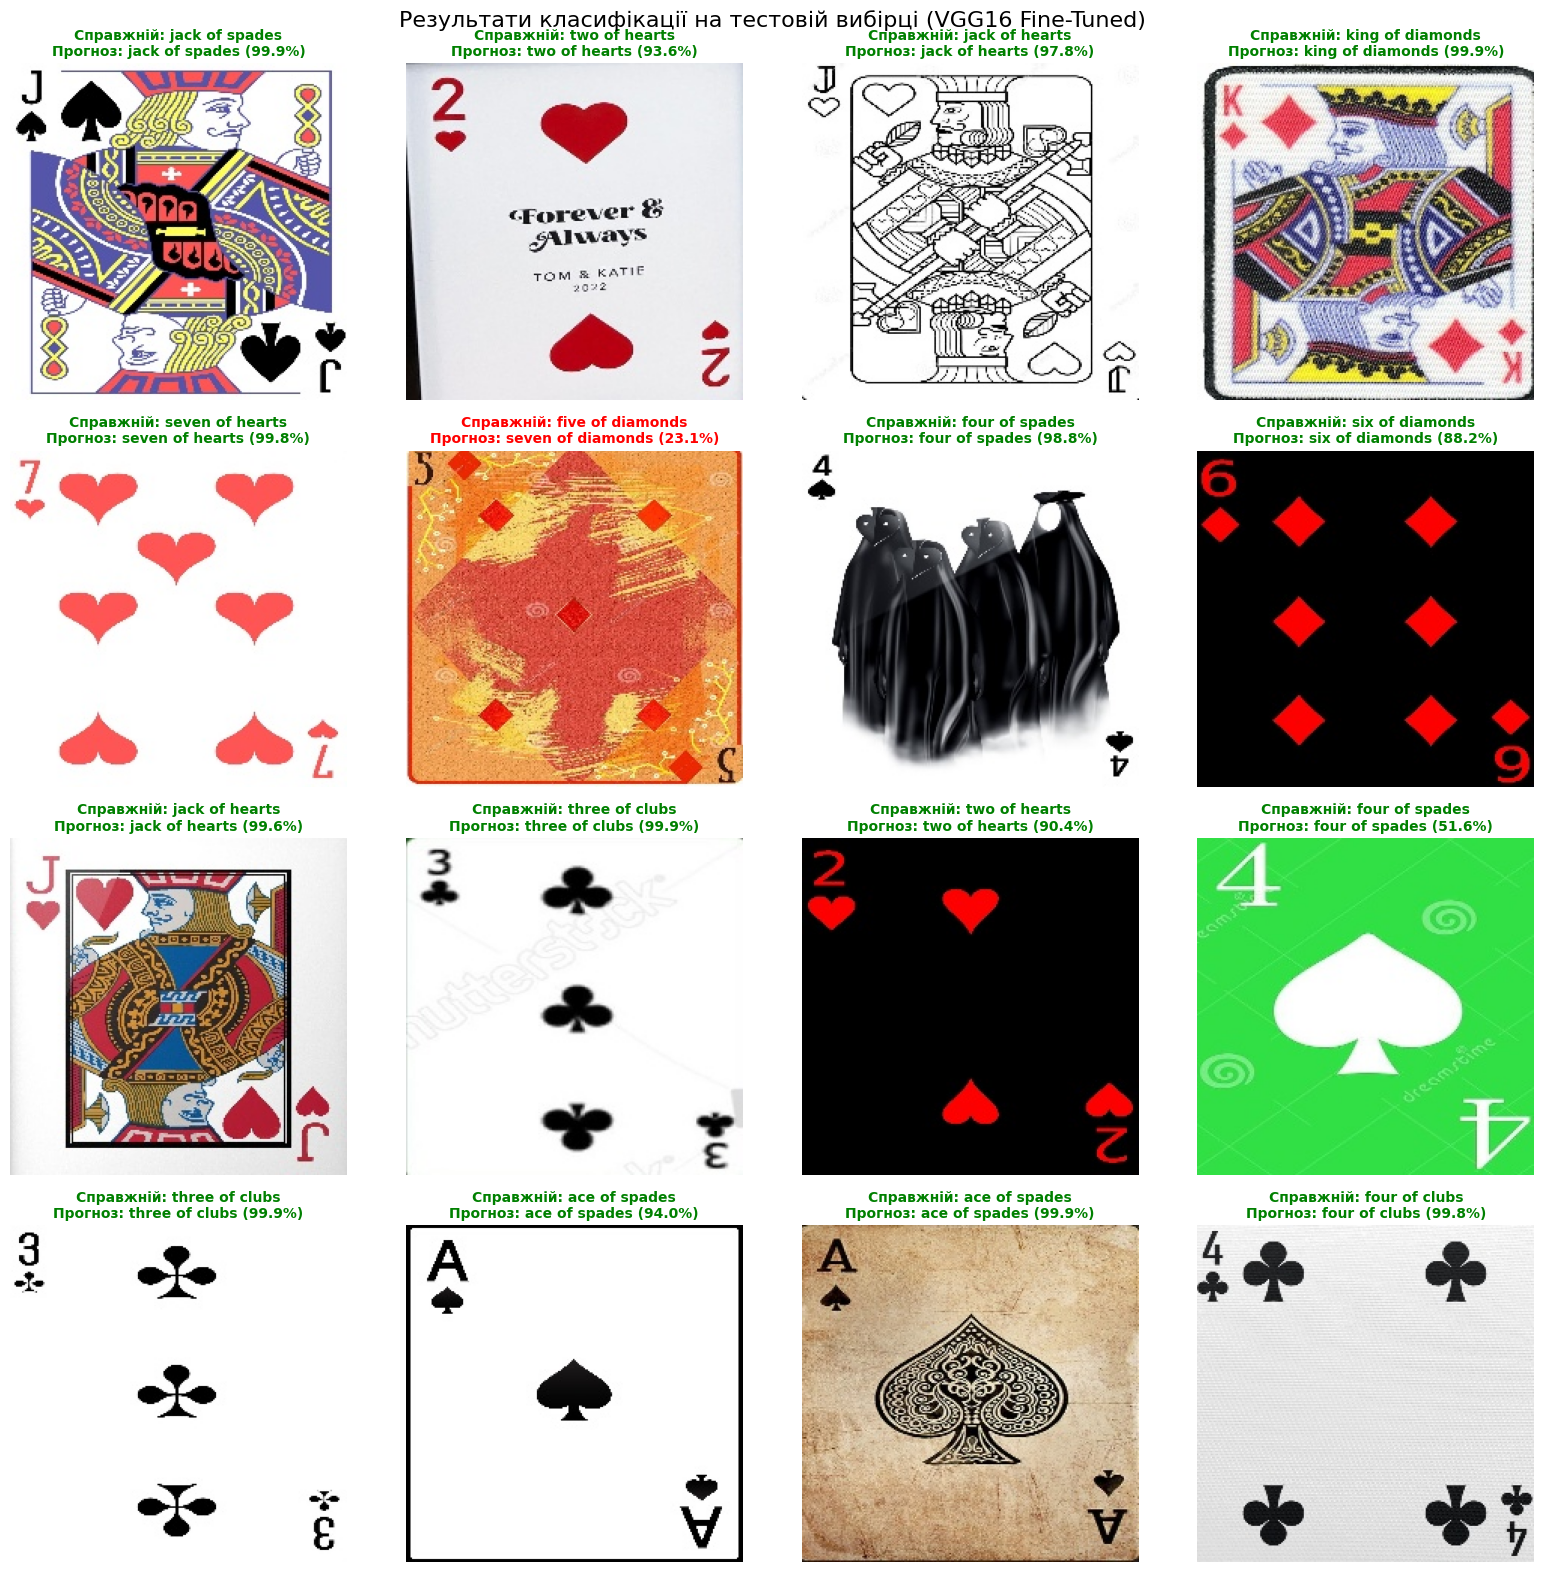

In [19]:
# Візуалізація результатів класифікації
filepaths = test_gen_vgg.filepaths
indices = random.sample(range(len(filepaths)), 16)

plt.figure(figsize=(16, 16))
for i, idx in enumerate(indices):
    img = Image.open(filepaths[idx])
    true_label = idx_to_class[true_classes[idx]]
    pred_label = idx_to_class[pred_classes[idx]]
    confidence = pred_probs[idx][pred_classes[idx]] * 100

    is_correct = (true_label == pred_label)
    color = 'green' if is_correct else 'red'

    plt.subplot(4, 4, i + 1)
    plt.imshow(img)
    plt.title(
        f"Справжній: {true_label}\nПрогноз: {pred_label} ({confidence:.1f}%)",
        color=color,
        fontsize=10,
        fontweight='bold'
    )
    plt.axis('off')

plt.suptitle('Результати класифікації на тестовій вибірці (VGG16 Fine-Tuned)', fontsize=16)
plt.tight_layout()
plt.show()

Кількість помилок на тестовій вибірці: 34 із 265


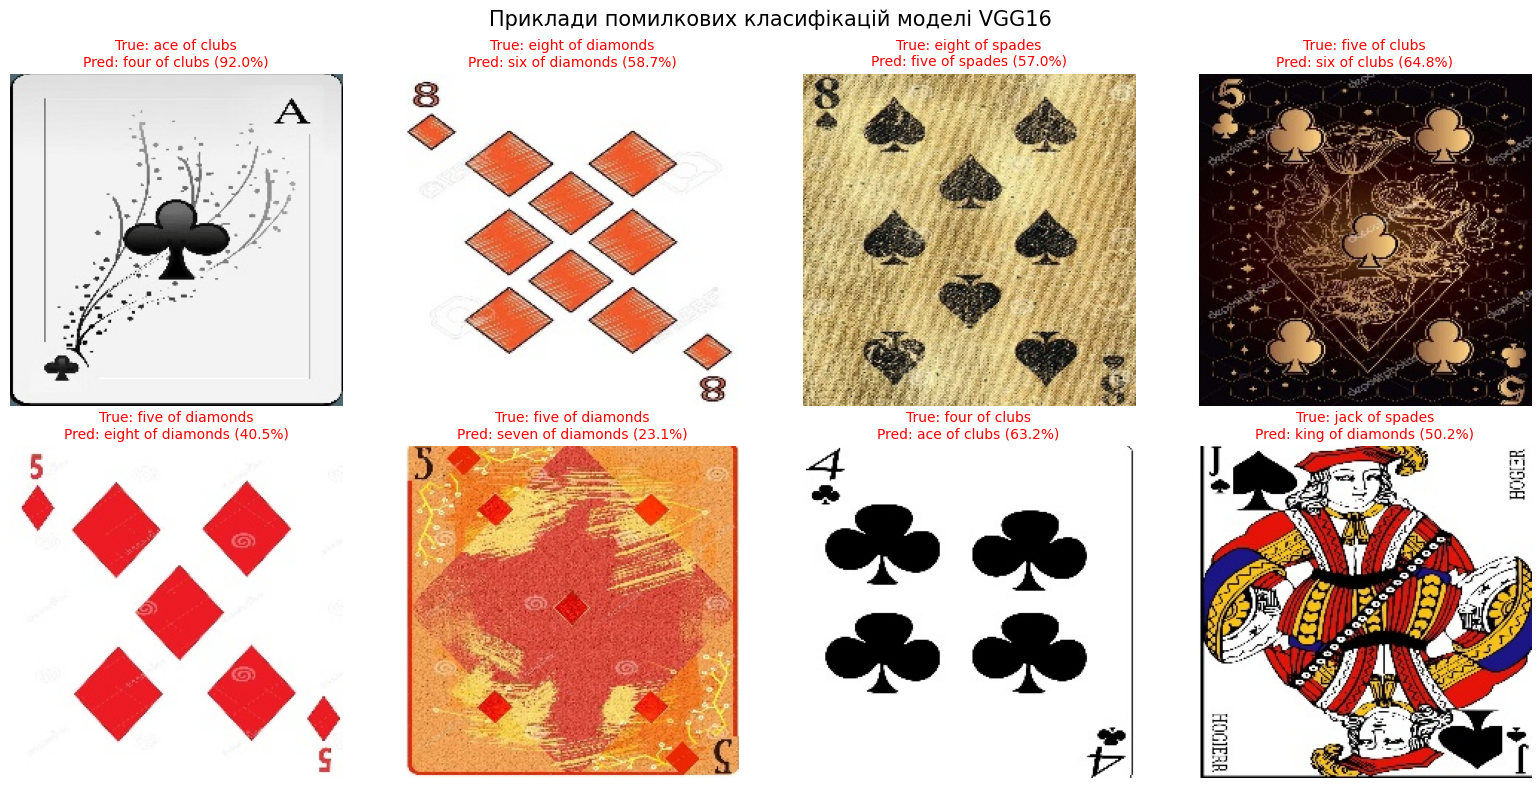

In [20]:
# Помилкові передбачення
errors = np.where(pred_classes != true_classes)[0]
print(f"Кількість помилок на тестовій вибірці: {len(errors)} із {len(true_classes)}")

if len(errors) > 0:
    sample_errors = errors[:min(8, len(errors))]
    plt.figure(figsize=(16, 8))
    for i, idx in enumerate(sample_errors):
        img = Image.open(filepaths[idx])
        true_label = idx_to_class[true_classes[idx]]
        pred_label = idx_to_class[pred_classes[idx]]
        confidence = pred_probs[idx][pred_classes[idx]] * 100

        plt.subplot(2, 4, i + 1)
        plt.imshow(img)
        plt.title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)", color='red', fontsize=10)
        plt.axis('off')
    plt.suptitle('Приклади помилкових класифікацій моделі VGG16', fontsize=15)
    plt.tight_layout()
    plt.show()

Висновки
1. **Аналіз та підготовка даних:**
   - Набір даних *Cards Image Dataset* містить **53 збалансовані класи** зображень розміром $224 x 224$ пікселів.
   - Застосування аугментації даних (випадкові повороти, зсуви, масштабування) дозволило зменшити перенавчання на тренувальній вибірці.

2. **Порівняння моделей (Custom CNN vs VGG16):**
   - **Власна згорткова мережа (Custom CNN):** показала гідну базову якість завдяки використанню блоків `Conv2D + BatchNormalization + MaxPooling2D` та `GlobalAveragePooling2D`, однак для 53 дрібних класів (де різниця між картами часто полягає лише в невеликому символі масті чи рангу в кутку) навчання з нуля потребує значно більше часу та схильне до насичення.
   - **VGG16 з донавчанням (Fine-Tuning):** використання попередньо навчених ваг ImageNet у поєднанні з двоетапним навчанням (спочатку заморожена основа, потім розморожування `block4` та `block5` із низьким `learning_rate = 1e-5`) забезпечило суттєво вищу точність та швидшу збіжність.

3. **Роль регуляризації та колбеків:**
   - `EarlyStopping` автоматично зупинив навчання при виході `val_loss` на плато та відновив найкращі ваги моделі.
   - `ReduceLROnPlateau` забезпечив плавне зменшення кроку навчання для точнішого налаштування ваг на пізніх епохах.

4. **Аналіз помилок:**
   - Більшість поодиноких помилок виникає між візуально схожими картами одного рангу або однієї масті (наприклад, *валет/дама/король* або картки зі стилізованим дизайном сорочки/ілюстрації).